# Módulo 02: KPIs y los 4 tipos de análisis

**Caso:** somos el equipo de analítica de una **inmobiliaria** en Ames (Iowa, EE. UU.). Tenemos el histórico de **1460 ventas de casas** entre 2006 y 2010.

La gerencia nos pregunta:
1. ¿Cómo nos fue? → **descriptivo**
2. ¿Por qué? → **diagnóstico**
3. ¿Cuánto valdrá una casa nueva que nos llegue? → **predictivo**
4. ¿Qué le recomendamos a un dueño que quiere vender mejor? → **prescriptivo**

> Basado en `sesion_1_intro_bi.pdf` (profesor Oscar N. Gómez).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from intro_analitica.datos import cargar_house_prices

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.0f}".format)

df = cargar_house_prices()
print(df.shape)
df[["Neighborhood", "OverallQual", "GrLivArea", "YrSold", "MoSold", "SalePrice"]].head()

Matplotlib is building the font cache; this may take a moment.


(1460, 81)


,Neighborhood,OverallQual,GrLivArea,YrSold,MoSold,SalePrice
0,CollgCr,7,1710,2008,2,208500
1,Veenker,6,1262,2007,5,181500
2,CollgCr,7,1786,2008,9,223500
3,Crawfor,7,1717,2006,2,140000
4,NoRidge,8,2198,2008,12,250000


Las columnas que usaremos hoy (el diccionario completo está en `data/raw/house_prices/data_description.txt`):

| Columna | Significado |
|---|---|
| `SalePrice` | Precio de venta (USD): **nuestro "ingreso"** |
| `YrSold`, `MoSold` | Año y mes de venta |
| `Neighborhood` | Barrio |
| `OverallQual` | Calidad general de materiales y acabados (1 a 10) |
| `GrLivArea` | Área habitable sobre el suelo (pies²) |

Como estamos en Colombia, convertimos el área a **m²** (1 pie² = 0.0929 m²).

In [2]:
df["area_m2"] = df["GrLivArea"] * 0.092903
df["precio_m2"] = df["SalePrice"] / df["area_m2"]
df[["GrLivArea", "area_m2", "SalePrice", "precio_m2"]].head()

,GrLivArea,area_m2,SalePrice,precio_m2
0,1710,159,208500,"1,312"
1,1262,117,181500,"1,548"
2,1786,166,223500,"1,347"
3,1717,160,140000,878
4,2198,204,250000,"1,224"


---
## 1️⃣ Análisis descriptivo: ¿qué pasó?

Empezamos por las **tarjetas de KPIs**, lo primero que muestra cualquier dashboard.

In [3]:
kpis = {
    "Casas vendidas": len(df),
    "Ingreso total (USD M)": df["SalePrice"].sum() / 1e6,
    "Precio mediano (USD)": df["SalePrice"].median(),
    "Precio promedio (USD)": df["SalePrice"].mean(),
    "Precio mediano por m² (USD)": df["precio_m2"].median(),
}
for nombre, valor in kpis.items():
    print(f"{nombre:<30} {valor:>12,.0f}")

Casas vendidas                        1,460
Ingreso total (USD M)                   264
Precio mediano (USD)                163,000
Precio promedio (USD)               180,921
Precio mediano por m² (USD)           1,293


**¿Por qué el promedio es mayor que la mediana?** Porque hay casas muy caras (hasta USD 755.000) que "jalan" el promedio hacia arriba.
Cuando la distribución es asimétrica, la **mediana** representa mejor la casa "típica".

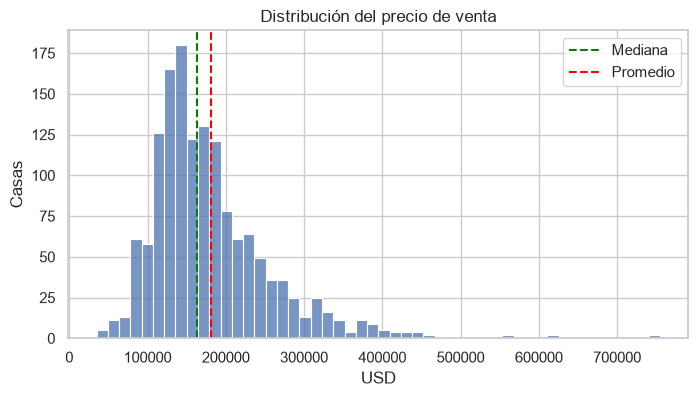

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df["SalePrice"], bins=50, ax=ax)
ax.axvline(df["SalePrice"].median(), color="green", ls="--", label="Mediana")
ax.axvline(df["SalePrice"].mean(), color="red", ls="--", label="Promedio")
ax.set(title="Distribución del precio de venta", xlabel="USD", ylabel="Casas")
ax.legend()
plt.show()

### Ventas por año

In [5]:
por_anio = df.groupby("YrSold").agg(ventas=("SalePrice", "size"), precio_mediano=("SalePrice", "median"))
por_anio

,ventas,precio_mediano
YrSold,,
2006,314,"163,995"
2007,329,"167,000"
2008,304,"164,000"
2009,338,"162,000"
2010,175,"155,000"


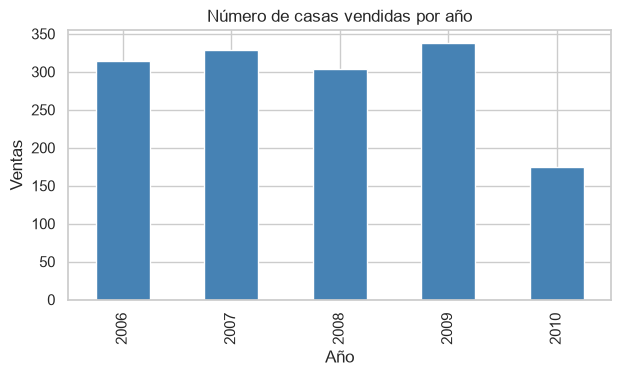

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
por_anio["ventas"].plot(kind="bar", ax=ax, color="steelblue")
ax.set(title="Número de casas vendidas por año", xlabel="Año", ylabel="Ventas")
plt.show()

**¡Las ventas de 2010 se desplomaron casi a la mitad!** ¿Le decimos a la gerencia que 2010 fue un año terrible?

Antes de concluir, hagamos **análisis diagnóstico**.

---
## 2️⃣ Análisis diagnóstico: ¿por qué pasó?

### Hipótesis 1: ¿el año 2010 está completo?

In [7]:
df.groupby("YrSold")["MoSold"].agg(["min", "max"])

,min,max
YrSold,,
2006,1,12
2007,1,12
2008,1,12
2009,1,12
2010,1,7


**¡Ahí está!** Los datos de 2010 solo llegan hasta **julio** (mes 7). No es que se vendiera menos: **el periodo está incompleto**.

Para comparar justo, comparemos **los mismos meses** (enero a julio) de cada año:

In [8]:
ene_jul = df[df["MoSold"] <= 7]
ene_jul.groupby("YrSold").size().rename("ventas_ene_jul")

YrSold
2006    224
2007    220
2008    205
2009    224
2010    175
Name: ventas_ene_jul, dtype: int64

Comparando lo comparable, la caída de 2010 pasa de **~48 %** a **~20 %** (175 ventas frente a unas 220 en los años anteriores).
Sigue habiendo una baja, que coincide con los años posteriores a la **crisis hipotecaria de 2008** en EE. UU., pero es mucho menor de lo que parecía.

**Lección:** un dashboard sin contexto puede llevar a decisiones equivocadas. Primero revisa que los periodos sean comparables y luego busca causas externas.

### Hipótesis 2: ¿hay estacionalidad?

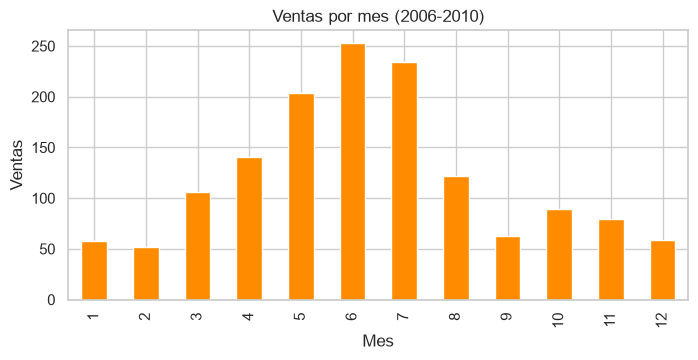

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
df.groupby("MoSold").size().plot(kind="bar", ax=ax, color="darkorange")
ax.set(title="Ventas por mes (2006-2010)", xlabel="Mes", ylabel="Ventas")
plt.show()

Las ventas se concentran entre **mayo y julio** (verano en EE. UU., cuando las familias se mudan antes del inicio de clases).
Esto es útil para el negocio: **planear el personal y la publicidad para esos meses**.

### Hipótesis 3: ¿por qué unos barrios son más caros? (*drill-down*)

In [10]:
barrios = (
    df.groupby("Neighborhood")
    .agg(ventas=("SalePrice", "size"), precio_mediano=("SalePrice", "median"),
         calidad_mediana=("OverallQual", "median"), precio_m2=("precio_m2", "median"))
    .sort_values("precio_mediano", ascending=False)
)
pd.concat([barrios.head(3), barrios.tail(3)])

,ventas,precio_mediano,calidad_mediana,precio_m2
Neighborhood,,,,
NridgHt,77,"315,000",8,"1,700"
NoRidge,41,"301,500",8,"1,380"
StoneBr,25,"278,000",8,"1,699"
BrDale,16,"106,000",6,981
IDOTRR,37,"103,000",5,975
MeadowV,17,"88,000",4,991


Los barrios caros (`NridgHt`, `NoRidge`, `StoneBr`) también tienen **mayor calidad mediana** (8 frente a 4-6).
¿Será la **calidad** lo que explica el precio, más que el barrio en sí?

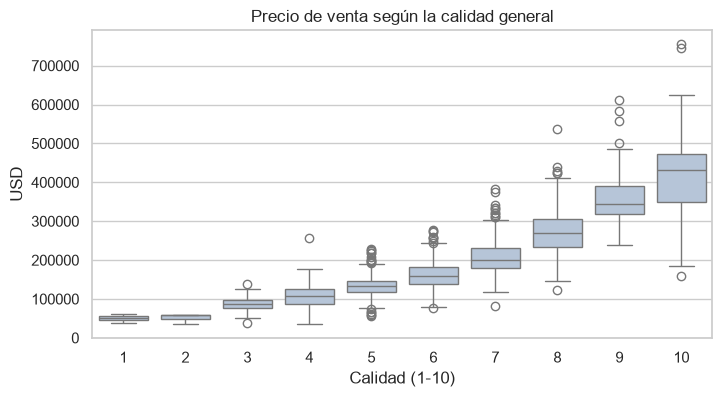

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", ax=ax, color="lightsteelblue")
ax.set(title="Precio de venta según la calidad general", xlabel="Calidad (1-10)", ylabel="USD")
plt.show()

In [12]:
df.groupby("OverallQual")["SalePrice"].median().to_frame("precio_mediano")

,precio_mediano
OverallQual,
1,"50,150"
2,"60,000"
3,"86,250"
4,"108,000"
5,"133,000"
6,"160,000"
7,"200,141"
8,"269,750"
9,"345,000"


Una casa de calidad 10 vale unas **8 veces** lo que vale una de calidad 1. La calidad es un factor muy fuerte.

> **Correlación ≠ causalidad.** Las casas de calidad alta también suelen ser más grandes y nuevas. El diagnóstico nos da **hipótesis** que después validamos con modelos.

---
## 3️⃣ Análisis predictivo: ¿qué pasará?

Un adelanto del módulo 06: con una **regresión lineal** de una sola variable (el área) estimamos el precio de una casa nueva.

In [13]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()
modelo.fit(df[["area_m2"]], df["SalePrice"])

print(f"Precio ≈ {modelo.intercept_:,.0f} + {modelo.coef_[0]:,.0f} × m²")
for m2 in [100, 150, 200]:
    print(f"Casa de {m2} m² → USD {modelo.predict(pd.DataFrame({'area_m2': [m2]}))[0]:,.0f}")

Precio ≈ 18,569 + 1,153 × m²
Casa de 100 m² → USD 133,883
Casa de 150 m² → USD 191,540
Casa de 200 m² → USD 249,197


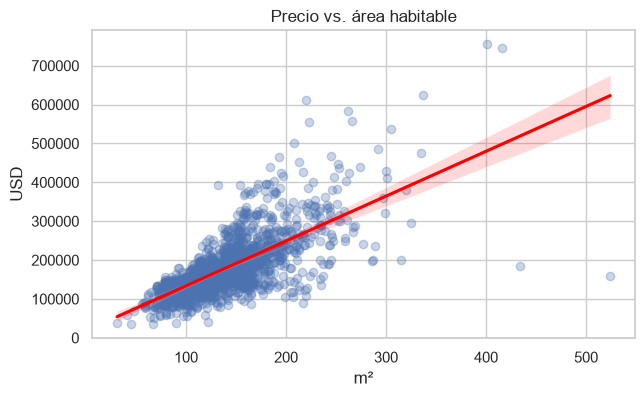

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.regplot(data=df, x="area_m2", y="SalePrice", scatter_kws={"alpha": 0.3}, line_kws={"color": "red"}, ax=ax)
ax.set(title="Precio vs. área habitable", xlabel="m²", ylabel="USD")
plt.show()

---
## 4️⃣ Análisis prescriptivo: ¿qué debo hacer?

El prescriptivo convierte lo anterior en **acciones**. Un ejemplo sencillo: ¿cuánto se valoriza una casa si mejora un punto de calidad?

In [15]:
mediana_calidad = df.groupby("OverallQual")["SalePrice"].median()
incremento = (mediana_calidad.pct_change() * 100).round(1).rename("incremento_%_al_subir_1_punto")
incremento.to_frame().T

OverallQual,1,2,3,4,5,6,7,8,9,10
incremento_%_al_subir_1_punto,NaN,20,44,25,23,20,25,35,28,25


**Recomendaciones para la gerencia (ejemplo):**

1. Concentrar la publicidad y el personal entre **mayo y julio**.
2. A los dueños con casas de calidad 5-6 se les puede sugerir **remodelar acabados**: pasar de 6 a 7 se asocia con un precio ~25 % mayor.
3. En los reportes, comparar siempre **periodos completos** (lección de 2010).

> El prescriptivo "de verdad" usa optimización o simulación; aquí la idea es entender el **salto de "qué pasó" a "qué hacer"**.

---
## Ejercicios guiados (15 min)

1. **KPI nuevo:** calcula el **precio mediano por m² por año**. ¿Subió o bajó entre 2006 y 2010? (pista: `groupby("YrSold")["precio_m2"].median()`)
2. **Diagnóstico:** la columna `SaleCondition` indica el tipo de venta (`Normal`, `Abnorml` = remate/embargo, `Partial` = casa nueva…). ¿Las ventas `Abnorml` tienen un precio mediano menor? ¿Por qué podría ser?
3. **Clasifica** estas preguntas en descriptivo, diagnóstico, predictivo o prescriptivo:
   - a) ¿Cuántas casas con piscina se vendieron?
   - b) ¿Qué precio debería pedir por mi casa?
   - c) ¿Por qué las casas de `NoRidge` son más caras?
   - d) ¿A qué casas les conviene remodelar la cocina antes de vender?

Soluciones en `ejercicios/soluciones/solucion_02.py`.

In [16]:
# Tu código aquí